# Cuadernillo 4 · Modelos y matrices de confusión

**Autor:** Dilan Aldana - Jeison Del Rio

**Objetivo.** Comparar tres modelos, ver qué tipo de error comete el mejor y ajustar una configuración para reducir el error que más cuesta.

**Fecha:** 22 de noviembre de 2026

**Desarrollo.** Comparar los modelos, leer la matriz de confusión, ajustar el hiperparámetro `C` enfocándose en un tipo de error y mostrar la nueva matriz. Al final, una **conclusión** con el modelo elegido y el motivo del ajuste.

In [1]:

# Python básico
import sys
import warnings
from pathlib import Path

# Datos y gráficos
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Modelos y métricas
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(RAIZ))

from funciones import analisis

warnings.filterwarnings("ignore")
analisis.configurar_estilo()

print("Todo listo")


Todo listo


**Qué hace esta celda.** Prepara los modelos y métricas de `scikit-learn`, los gráficos y las funciones del proyecto. `Pipeline` encadena pasos y `GridSearchCV` prueba configuraciones.

## Preparación

El cuaderno se puede ejecutar solo: esta celda repite los pasos de los cuadernillos 1 a 3 (leer, limpiar, transformar y separar).

In [2]:

# Preparación: se repiten los pasos de los cuadernillos 1 a 3
# para que este cuaderno funcione solo.
df = pd.read_csv(RAIZ / "datos" / "solicitudes_prestamos.csv")
df["Aprobado"] = (df["Loan_Status"] == "Y").astype(int)

df = df.drop(columns="Loan_ID")
df["Dependents"] = df["Dependents"].replace("3+", "3").astype(float)
for columna in ["Gender", "Married", "Self_Employed"]:
    df[columna] = df[columna].fillna("Sin dato")

df["Ingreso_Total"] = df["ApplicantIncome"] + df["CoapplicantIncome"]
df = df.drop(columns=["ApplicantIncome", "CoapplicantIncome"])

y = df.pop("Aprobado")
X = pd.get_dummies(df.drop(columns="Loan_Status"), drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Entrenamiento: {X_train.shape[0]} solicitudes")
print(f"Prueba:        {X_test.shape[0]} solicitudes")
print(f"Variables:     {X.shape[1]}")


Entrenamiento: 491 solicitudes
Prueba:        123 solicitudes
Variables:     14


Los datos quedan como al final del cuadernillo 3: **491 para entrenar, 123 para probar y 14 columnas**.

## 1. Los modelos

- **Base:** dice siempre "aprobado". No aprende; sirve para saber cuánto mejora un modelo real.
- **Regresión logística:** calcula una probabilidad a partir de las variables. Es lineal y se puede explicar.
- **Random Forest:** cientos de árboles que votan. Capta relaciones complejas, pero con pocos datos puede memorizar.

Cada uno se entrena con 491 solicitudes y se evalúa con las 123 que no vio.

In [3]:
def crear_logistica(C=1):
    """Pipeline de regresión logística; C controla la regularización."""
    return Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
        ("modelo", LogisticRegression(
            C=C, max_iter=2000, class_weight="balanced", random_state=42
        )),
    ])


modelos = {
    "Base (siempre aprueba)": Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("modelo", DummyClassifier(strategy="most_frequent")),
    ]),

    "Regresión logística": crear_logistica(),

    "Random Forest": Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("modelo", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                          random_state=42, n_jobs=-1)),
    ]),
}

resultados = []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    resultados.append(analisis.evaluar(nombre, modelo, X_train, y_train, X_test, y_test))

tabla = analisis.tabla_resultados(resultados)
tabla

,modelo,auc_train,auc_test,brecha,exactitud,precision,recall,f1
1,Regresión logística,0.767,0.851,-0.084,0.829,0.872,0.882,0.877
2,Random Forest,1.000,0.826,0.174,0.780,0.854,0.824,0.838
0,Base (siempre aprueba),0.500,0.500,0.000,0.691,0.691,1.000,0.817


**Cómo se lee la tabla.** **AUC** mide qué tan bien ordena las solicitudes de más a menos probable (0,50 = azar, 1,00 = perfecto). **Exactitud** es el porcentaje de aciertos. **Recall** es la proporción de aprobados que detecta. **F1** combina precisión y recall. **Brecha** es la diferencia entre el AUC de entrenamiento y el de prueba: si es grande, el modelo memorizó.

La **regresión logística** gana (AUC 0,851, exactitud 82,9 %). El **base** acierta 69,1 % solo porque la mayoría se aprueba; su AUC de 0,50 muestra que no distingue nada. El **Random Forest** queda atrás (0,826) con una brecha de **+0,174**.

También pesa que la logística se puede explicar, algo importante cuando hay que justificar un rechazo (cuadernillo 5).

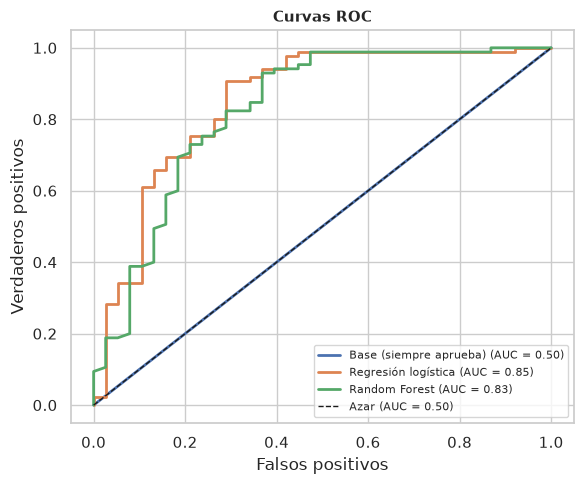

In [4]:
analisis.graficar_roc(modelos, X_test, y_test)

**Curva ROC.** Cada punto representa un punto de corte distinto para aprobar. El eje horizontal son los **falsos positivos** (rechazados que el modelo aprobaría) y el vertical, los **verdaderos positivos** (aprobados que detecta). La diagonal es adivinar al azar.

Cuanto más arriba y a la izquierda queda la curva (muchos aciertos con pocos falsos positivos), mejor separa el modelo. El área bajo la curva (**AUC**) resume eso en un número.

La logística (AUC 0,85) y el Random Forest (0,83) están cerca y muy por encima del azar. El AUC compara modelos en general, pero no dice cuántos errores concretos se cometen: para eso está la matriz (sección 2).

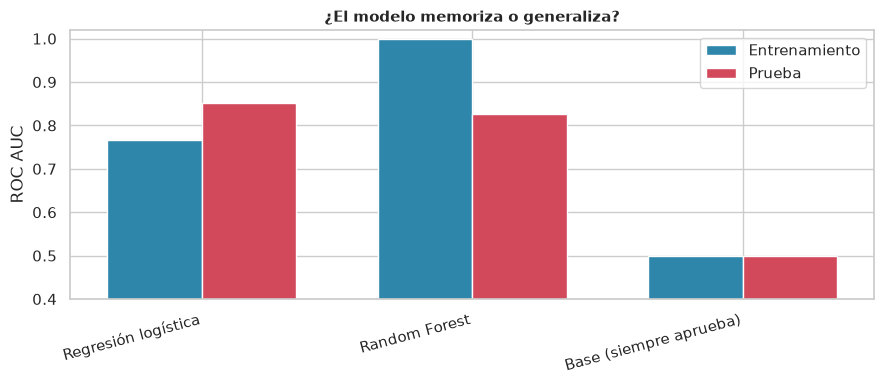

In [5]:
analisis.graficar_train_test(tabla)

**Qué muestra.** Compara el AUC de entrenamiento (azul) con el de prueba (rojo).

El **Random Forest** saca 1,00 en entrenamiento y 0,83 en prueba: la caída de 17 puntos es **sobreajuste**, aprendió de memoria. La **logística** va de 0,77 a 0,85: rinde igual o mejor con datos nuevos. Por eso se descarta el bosque y se sigue con la logística.

## 2. Matriz de confusión del modelo

El AUC resume en un número, pero no dice **qué tipo de error** se comete. La matriz cruza la predicción con la realidad y reparte las 123 solicitudes de prueba en cuatro casillas. Se evalúa la logística en su configuración inicial (`C = 1`).

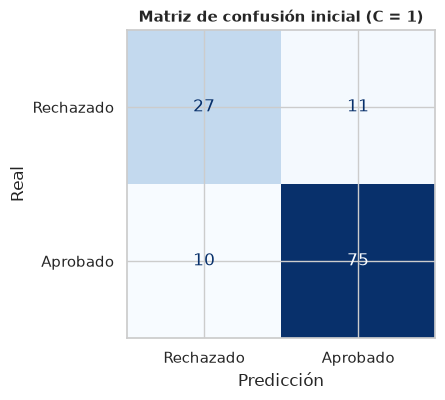

,casilla,significado,casos
0,Verdaderos negativos (TN),Rechazado y el modelo lo rechazó,27
1,Falsos positivos (FP),"Rechazado, pero el modelo lo aprobó",11
2,Falsos negativos (FN),"Aprobado, pero el modelo lo rechazó",10
3,Verdaderos positivos (TP),Aprobado y el modelo lo aprobó,75


              precision    recall  f1-score   support

   Rechazado      0.730     0.711     0.720        38
    Aprobado      0.872     0.882     0.877        85

    accuracy                          0.829       123
   macro avg      0.801     0.796     0.799       123
weighted avg      0.828     0.829     0.829       123



In [6]:
modelo_inicial = modelos["Regresión logística"]
prediccion_inicial = modelo_inicial.predict(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, prediccion_inicial).ravel()

tabla_inicial = pd.DataFrame({
    "casilla": ["Verdaderos negativos (TN)", "Falsos positivos (FP)",
                "Falsos negativos (FN)", "Verdaderos positivos (TP)"],
    "significado": ["Rechazado y el modelo lo rechazó",
                    "Rechazado, pero el modelo lo aprobó",
                    "Aprobado, pero el modelo lo rechazó",
                    "Aprobado y el modelo lo aprobó"],
    "casos": [tn, fp, fn, tp],
})

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, prediccion_inicial,
    display_labels=["Rechazado", "Aprobado"],
    cmap="Blues",
    colorbar=False,
)
disp.ax_.set_xlabel("Predicción")
disp.ax_.set_ylabel("Real")
disp.ax_.set_title("Matriz de confusión inicial (C = 1)")
plt.show()

display(tabla_inicial)

print(classification_report(
    y_test, prediccion_inicial,
    target_names=["Rechazado", "Aprobado"],
    digits=3,
))

**Cómo se lee.** Filas = realidad, columnas = predicción. La diagonal son aciertos; las otras dos casillas, errores.

- **27 TN y 75 TP:** aciertos (rechazados y aprobados bien clasificados).
- **11 FP:** rechazados que el modelo aprobó.
- **10 FN:** aprobados que el modelo rechazó.

Acierta **102 de 123 (82,9 %)**.

**¿Dónde conviene enfocarse?** En los **falsos negativos**. Un FP no entrega el dinero: toda aprobación pasa por revisión de documentos, así que cuesta una revisión. Un FN termina el proceso: el cliente recibe un "no" y no hay revisión que lo recupere. Con un 68,7 % de aprobaciones, esos buenos clientes son la mayoría del negocio.

La métrica que mide eso es el **recall**: de los aprobados reales, cuántos detecta el modelo. Subirlo reduce los FN.

## 3. Ajuste de hiperparámetros

Un **hiperparámetro** es una configuración que se elige antes de entrenar, como una perilla. El único que se mueve es **`C`**, que controla la regularización: un `C` grande deja al modelo ajustarse mucho a los datos (riesgo de memorizar) y uno pequeño lo vuelve más prudente, con probabilidades menos extremas.

Se mantienen fijos `class_weight="balanced"` (compensación del desbalanceo, cuadernillo 1) y el corte de 0,5.

**Cómo se elige.** Con **validación cruzada de 5 partes**: el entrenamiento se divide en 5 grupos; se entrena con 4 y se prueba con el restante, rotando hasta que cada grupo sea prueba una vez, y se promedian los 5 resultados. Se optimiza **recall**, porque el foco son los FN; el AUC no dice cuántos aprobados quedan fuera con el corte de 0,5.

Hay un solo hiperparámetro con 6 valores, así que se prueban todos.

In [7]:
busqueda = GridSearchCV(
    crear_logistica(),
    {"modelo__C": [0.01, 0.05, 0.1, 0.5, 1, 10]},
    cv=5,
    scoring="recall",
    n_jobs=-1,
)

busqueda.fit(X_train, y_train)

print("Mejor valor de C:", busqueda.best_params_["modelo__C"])
print(f"Recall promedio en validación cruzada: {busqueda.best_score_:.3f}")

Mejor valor de C: 0.01
Recall promedio en validación cruzada: 0.920


El mejor valor es **`C = 0,01`**, con recall medio de **0,920** en las 5 vueltas. La regularización fuerte vuelve al modelo más prudente y reduce los rechazos indebidos.

In [8]:
tabla_cv = pd.DataFrame({
    "C": busqueda.cv_results_["param_modelo__C"].astype(float),
    "recall_medio": busqueda.cv_results_["mean_test_score"],
    "desviacion": busqueda.cv_results_["std_test_score"],
}).sort_values("C")

tabla_cv.round(3)

,C,recall_medio,desviacion
0,0.01,0.920,0.027
1,0.05,0.902,0.012
2,0.10,0.878,0.022
3,0.50,0.867,0.033
4,1.00,0.864,0.035
5,10.00,0.864,0.028


Cada fila es un valor de `C`; `recall_medio` promedia las 5 vueltas y `desviacion` indica cuánto varió. `C = 0,01` gana (0,920); al subir `C`, el recall baja hasta 0,864. La desviación es pequeña en todos, así que la diferencia no es casualidad.

In [9]:
modelo_final = busqueda.best_estimator_

comparacion = pd.DataFrame([
    analisis.evaluar("Logística con C=1", modelos["Regresión logística"],
                   X_train, y_train, X_test, y_test),
    analisis.evaluar(f"Logística con C={busqueda.best_params_['modelo__C']}",
                   modelo_final, X_train, y_train, X_test, y_test),
])
comparacion.round(3)

,modelo,auc_train,auc_test,exactitud,precision,recall,f1
0,Logística con C=1,0.767,0.851,0.829,0.872,0.882,0.877
1,Logística con C=0.01,0.765,0.844,0.846,0.851,0.941,0.894


**Qué cambió al pasar de C = 1 a C = 0,01**

- **Recall: 88,2 % → 94,1 %.** De cada 100 aprobados reales, detecta 94 en vez de 88.
- **Exactitud: 82,9 % → 84,6 %** y **F1: 0,877 → 0,894**.
- **Precisión: 87,2 % → 85,1 %.** Aprueba unas pocas más que estaban mal.
- **AUC: 0,851 → 0,844.** Una caída mínima, dentro de la variación de 123 casos.
- En validación cruzada también gana: **0,920** frente a **0,864**.

Al encoger los pesos, las probabilidades quedan más cerca de 0,5 y los casos dudosos tienden a aprobarse: bajan los FN y suben un poco los FP.

## 4. Nueva matriz de confusión

Se evalúa el modelo ajustado (`C = 0,01`) con las **mismas 123 solicitudes** y el **mismo corte de 0,5**. Solo cambió la configuración.

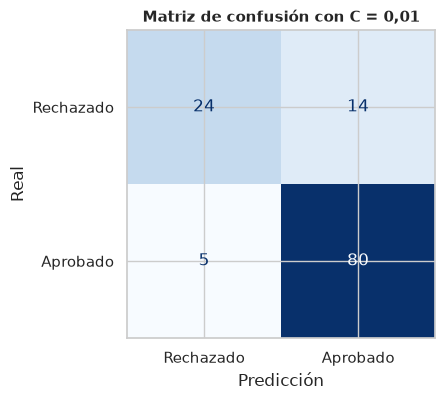

,casilla,C = 1,"C = 0,01",cambio
0,Verdaderos negativos (TN),27,24,-3
1,Falsos positivos (FP),11,14,3
2,Falsos negativos (FN),10,5,-5
3,Verdaderos positivos (TP),75,80,5


              precision    recall  f1-score   support

   Rechazado      0.828     0.632     0.716        38
    Aprobado      0.851     0.941     0.894        85

    accuracy                          0.846       123
   macro avg      0.839     0.786     0.805       123
weighted avg      0.844     0.846     0.839       123



In [10]:
modelo_final = busqueda.best_estimator_
prediccion_final = modelo_final.predict(X_test)

tn_f, fp_f, fn_f, tp_f = confusion_matrix(y_test, prediccion_final).ravel()

comparacion_matriz = pd.DataFrame({
    "casilla": ["Verdaderos negativos (TN)", "Falsos positivos (FP)",
                "Falsos negativos (FN)", "Verdaderos positivos (TP)"],
    "C = 1": [tn, fp, fn, tp],
    "C = 0,01": [tn_f, fp_f, fn_f, tp_f],
})
comparacion_matriz["cambio"] = (
    comparacion_matriz["C = 0,01"] - comparacion_matriz["C = 1"]
)

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, prediccion_final,
    display_labels=["Rechazado", "Aprobado"],
    cmap="Blues",
    colorbar=False,
)
disp.ax_.set_xlabel("Predicción")
disp.ax_.set_ylabel("Real")
disp.ax_.set_title("Matriz de confusión con C = 0,01")
plt.show()

display(comparacion_matriz)

print(classification_report(
    y_test, prediccion_final,
    target_names=["Rechazado", "Aprobado"],
    digits=3,
))

- **FN: 10 → 5.** El cambio buscado: 5 clientes buenos que ya no se rechazan.
- **FP: 11 → 14.** El costo: 3 aprobaciones indebidas más, que la revisión de documentos debe detectar.
- **TP: 75 → 80** y **TN: 27 → 24.** El modelo se movió hacia aprobar.
- **Aciertos: 102 → 104 (82,9 % → 84,6 %).**

Se cambiaron 3 revisiones adicionales por 5 clientes recuperados. Si el banco prefiriera lo contrario, habría que dar más peso a los rechazados; el costo sería el inverso: más FN. Es una decisión de negocio y queda documentada.

## 5. Conclusión

- **Regresión logística:** el mejor modelo (AUC 0,851, exactitud 82,9 %, recall 88,2 %). El Random Forest sobreajustó (1,00 en entrenamiento, 0,83 en prueba) y se descartó.
- **Matriz inicial:** 10 falsos negativos, el error a atacar.
- **Ajuste de `C`:** optimizando recall con validación cruzada, el mejor valor fue **0,01** (recall 0,920 frente a 0,864).
- **Matriz nueva:** FN de 10 a 5, con 3 FP más; aciertos de 102 a 104 (82,9 % → 84,6 %).
- **Justificación:** un FP cuesta una revisión; un FN cuesta un cliente.

El cuadernillo 5 interpreta el modelo, explica una decisión concreta y lo guarda.